# EDA 01 - Cobertura geográfica de clientes y vendedores

Este notebook analiza si los códigos postales de clientes y vendedores pueden vincularse con la tabla de geolocalización de Olist.

## Objetivos

- Diferenciar un código postal faltante de un código postal sin correspondencia geográfica.
- Evitar uniones muchos-a-muchos con la tabla de geolocalización.
- Medir el impacto de la falta de coordenadas sobre la futura muestra analítica.
- Fundamentar el criterio metodológico para tratar estos casos en los modelos posteriores.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# Busca la carpeta del proyecto si el kernel se inicia desde Repos, TFI_ITBA o notebooks/.
candidatos = [Path.cwd(), Path.cwd().parent, Path.cwd() / "TFI_ITBA"]
PROYECTO = next((ruta for ruta in candidatos if (ruta / "data" / "parquet").exists()), None)
if PROYECTO is None:
    raise FileNotFoundError("No se encontró la carpeta data/parquet del proyecto.")

DATA_DIR = PROYECTO / "data" / "parquet"
print(f"Carpeta de datos: {DATA_DIR.resolve()}")

Carpeta de datos: C:\Users\daniel.fernandez\Desktop\Repos\TFI_ITBA\data\parquet


## 1. Carga de las tablas necesarias

Para este análisis sólo necesitamos clientes, vendedores, geolocalización, pedidos e ítems. No construiremos todavía el dataset final del modelo.

In [2]:
clientes = pd.read_parquet(DATA_DIR / "olist_customers_dataset.parquet")
vendedores = pd.read_parquet(DATA_DIR / "olist_sellers_dataset.parquet")
geolocalizacion = pd.read_parquet(DATA_DIR / "olist_geolocation_dataset.parquet")
pedidos = pd.read_parquet(DATA_DIR / "olist_orders_dataset.parquet")
items = pd.read_parquet(DATA_DIR / "olist_order_items_dataset.parquet")

tamanios = pd.DataFrame(
    {
        "tabla": ["clientes", "vendedores", "geolocalizacion", "pedidos", "items"],
        "filas": [len(clientes), len(vendedores), len(geolocalizacion), len(pedidos), len(items)],
        "columnas": [clientes.shape[1], vendedores.shape[1], geolocalizacion.shape[1], pedidos.shape[1], items.shape[1]],
    }
)
display(tamanios)

,tabla,filas,columnas
0,clientes,99441,5
1,vendedores,3095,4
2,geolocalizacion,1000163,5
3,pedidos,99441,8
4,items,112650,7


## 2. Calidad de los códigos postales

El análisis utiliza las variables `customer_zip_code_prefix`, `seller_zip_code_prefix` y `geolocation_zip_code_prefix`. Las dos primeras identifican el prefijo postal asociado al cliente y al vendedor, respectivamente. La tercera identifica el prefijo postal en la tabla de geolocalización y se utiliza como clave para incorporar las coordenadas.

Las tres variables están almacenadas como enteros. En consecuencia, los prefijos que comienzan con cero se representan con cuatro dígitos. Para conservar el formato postal de cinco posiciones en tablas y gráficos se genera una representación de texto mediante `zfill(5)`, sin alterar las claves originales utilizadas en las uniones.

In [3]:
resumen_postal = pd.DataFrame(
    {
        "tabla": ["clientes", "vendedores", "geolocalizacion"],
        "filas": [len(clientes), len(vendedores), len(geolocalizacion)],
        "nulos_codigo_postal": [
            clientes["customer_zip_code_prefix"].isna().sum(),
            vendedores["seller_zip_code_prefix"].isna().sum(),
            geolocalizacion["geolocation_zip_code_prefix"].isna().sum(),
        ],
        "prefijos_unicos": [
            clientes["customer_zip_code_prefix"].nunique(),
            vendedores["seller_zip_code_prefix"].nunique(),
            geolocalizacion["geolocation_zip_code_prefix"].nunique(),
        ],
    }
)
display(resumen_postal)

# Versiones de texto para mostrar los ceros iniciales sin modificar las claves originales.
clientes["zip_cliente"] = clientes["customer_zip_code_prefix"].astype("string").str.zfill(5)
vendedores["zip_vendedor"] = vendedores["seller_zip_code_prefix"].astype("string").str.zfill(5)

longitudes_clientes = clientes["customer_zip_code_prefix"].astype(str).str.len().value_counts().sort_index()
print("Longitud antes de agregar el cero inicial para presentación:")
display(longitudes_clientes.rename_axis("cantidad_digitos").to_frame("clientes"))

,tabla,filas,nulos_codigo_postal,prefijos_unicos
0,clientes,99441,0,14994
1,vendedores,3095,0,2246
2,geolocalizacion,1000163,0,19015


Longitud antes de agregar el cero inicial para presentación:


,clientes
cantidad_digitos,
4,23995
5,75446


## 3. Una fila geográfica por prefijo postal

La tabla de geolocalización contiene múltiples coordenadas para un mismo prefijo. Antes de unirla con clientes o vendedores, calculamos la mediana de latitud y longitud por prefijo. La mediana es menos sensible a coordenadas extremas que el promedio.

In [4]:
repeticiones_por_prefijo = geolocalizacion.groupby("geolocation_zip_code_prefix").size()

resumen_repeticiones = pd.Series(
    {
        "filas_geolocalizacion": len(geolocalizacion),
        "prefijos_unicos": geolocalizacion["geolocation_zip_code_prefix"].nunique(),
        "filas_duplicadas_por_prefijo": int((repeticiones_por_prefijo - 1).clip(lower=0).sum()),
        "maximo_registros_mismo_prefijo": int(repeticiones_por_prefijo.max()),
    },
    name="valor",
).to_frame()
display(resumen_repeticiones)

geo_por_prefijo = (
    geolocalizacion
    .groupby("geolocation_zip_code_prefix", as_index=False)
    .agg(
        latitud_mediana=("geolocation_lat", "median"),
        longitud_mediana=("geolocation_lng", "median"),
        observaciones_geo=("geolocation_zip_code_prefix", "size"),
    )
)

print(f"La tabla resumida tiene {len(geo_por_prefijo):,} filas y una fila por prefijo.")
display(geo_por_prefijo.head())

,valor
filas_geolocalizacion,1000163
prefijos_unicos,19015
filas_duplicadas_por_prefijo,981148
maximo_registros_mismo_prefijo,1146


La tabla resumida tiene 19,015 filas y una fila por prefijo.


,geolocation_zip_code_prefix,latitud_mediana,longitud_mediana,observaciones_geo
0,1001,-23.550381,-46.634027,26
1,1002,-23.548551,-46.635072,13
2,1003,-23.548977,-46.635313,17
3,1004,-23.549535,-46.634771,22
4,1005,-23.549612,-46.636532,25


## 4. Cobertura geográfica de clientes y vendedores

Un código postal puede estar informado en clientes o vendedores y, aun así, no existir en la tabla de geolocalización. Usamos una unión izquierda para conservar todos los registros y crear indicadores explícitos de cobertura.

In [5]:
clientes_geo = clientes.merge(
    geo_por_prefijo,
    left_on="customer_zip_code_prefix",
    right_on="geolocation_zip_code_prefix",
    how="left",
    validate="many_to_one",
)
clientes_geo["geo_disponible"] = clientes_geo["latitud_mediana"].notna() & clientes_geo["longitud_mediana"].notna()

vendedores_geo = vendedores.merge(
    geo_por_prefijo,
    left_on="seller_zip_code_prefix",
    right_on="geolocation_zip_code_prefix",
    how="left",
    validate="many_to_one",
)
vendedores_geo["geo_disponible"] = vendedores_geo["latitud_mediana"].notna() & vendedores_geo["longitud_mediana"].notna()

cobertura = pd.DataFrame(
    {
        "entidad": ["clientes", "vendedores"],
        "registros": [len(clientes_geo), len(vendedores_geo)],
        "con_geolocalizacion": [clientes_geo["geo_disponible"].sum(), vendedores_geo["geo_disponible"].sum()],
        "sin_geolocalizacion": [(~clientes_geo["geo_disponible"]).sum(), (~vendedores_geo["geo_disponible"]).sum()],
    }
)
cobertura["porcentaje_sin_geolocalizacion"] = (
    100 * cobertura["sin_geolocalizacion"] / cobertura["registros"]
).round(3)
display(cobertura)

,entidad,registros,con_geolocalizacion,sin_geolocalizacion,porcentaje_sin_geolocalizacion
0,clientes,99441,99163,278,0.280
1,vendedores,3095,3088,7,0.226


In [6]:
clientes_sin_geo = clientes_geo.loc[~clientes_geo["geo_disponible"]].copy()
vendedores_sin_geo = vendedores_geo.loc[~vendedores_geo["geo_disponible"]].copy()

resumen_clientes_sin_geo = pd.Series(
    {
        "registros_customer": len(clientes_sin_geo),
        "prefijos_diferentes": clientes_sin_geo["customer_zip_code_prefix"].nunique(),
        "clientes_unicos_afectados": clientes_sin_geo["customer_unique_id"].nunique(),
    },
    name="valor",
).to_frame()
display(resumen_clientes_sin_geo)

top_prefijos_sin_geo = (
    clientes_sin_geo
    .groupby(["zip_cliente", "customer_state", "customer_city"], as_index=False)
    .size()
    .sort_values("size", ascending=False)
    .rename(columns={"size": "cantidad_clientes"})
    .head(20)
)
print("Prefijos sin geolocalización con mayor frecuencia:")
display(top_prefijos_sin_geo)

,valor
registros_customer,278
prefijos_diferentes,157
clientes_unicos_afectados,269


Prefijos sin geolocalización con mayor frecuencia:


,zip_cliente,customer_state,customer_city,cantidad_clientes
69,70686,DF,brasilia,15
95,72005,DF,brasilia,13
86,71919,DF,brasilia,10
130,73255,DF,brasilia,7
104,72300,DF,brasilia,6
133,73369,DF,brasilia,5
84,71884,DF,brasilia,5
94,72002,DF,brasilia,5
135,73401,DF,brasilia,5
81,71676,DF,brasilia,4


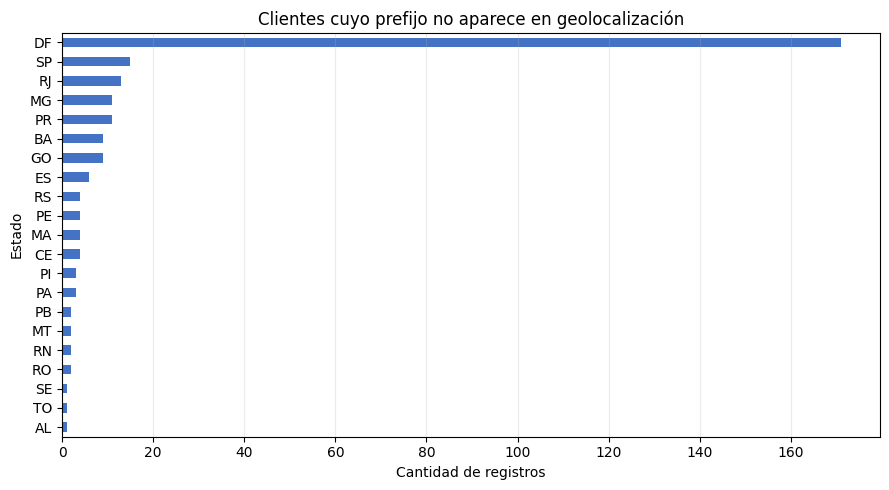

In [7]:
faltantes_por_estado = clientes_sin_geo["customer_state"].value_counts().sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(9, 5))
faltantes_por_estado.plot(kind="barh", ax=ax, color="#4472C4")
ax.set_title("Clientes cuyo prefijo no aparece en geolocalización")
ax.set_xlabel("Cantidad de registros")
ax.set_ylabel("Estado")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

## 5. Impacto sobre la muestra principal del TFI

En concordancia con la unidad de análisis definida para el TFI, la muestra se restringe a pedidos entregados y con un único ítem. En esta etapa se utiliza esa muestra exclusivamente para cuantificar la disponibilidad de las coordenadas necesarias para calcular la distancia entre cliente y vendedor; todavía no se construye la base final de modelado.

In [8]:
cantidad_items = items.groupby("order_id").size().rename("cantidad_items")

pedidos_con_cantidad = pedidos.merge(
    cantidad_items,
    left_on="order_id",
    right_index=True,
    how="left",
    validate="one_to_one",
)

pedidos_muestra = pedidos_con_cantidad.loc[
    pedidos_con_cantidad["order_status"].eq("delivered")
    & pedidos_con_cantidad["cantidad_items"].eq(1)
].copy()

items_muestra = items[items["order_id"].isin(pedidos_muestra["order_id"])].copy()

base = (
    pedidos_muestra
    .merge(clientes, on="customer_id", how="left", validate="many_to_one")
    .merge(items_muestra, on="order_id", how="left", validate="one_to_one")
    .merge(vendedores, on="seller_id", how="left", validate="many_to_one")
)

geo_cliente = geo_por_prefijo.rename(
    columns={
        "geolocation_zip_code_prefix": "customer_geo_zip",
        "latitud_mediana": "latitud_cliente",
        "longitud_mediana": "longitud_cliente",
        "observaciones_geo": "observaciones_geo_cliente",
    }
)
geo_vendedor = geo_por_prefijo.rename(
    columns={
        "geolocation_zip_code_prefix": "seller_geo_zip",
        "latitud_mediana": "latitud_vendedor",
        "longitud_mediana": "longitud_vendedor",
        "observaciones_geo": "observaciones_geo_vendedor",
    }
)

base = (
    base
    .merge(
        geo_cliente,
        left_on="customer_zip_code_prefix",
        right_on="customer_geo_zip",
        how="left",
        validate="many_to_one",
    )
    .merge(
        geo_vendedor,
        left_on="seller_zip_code_prefix",
        right_on="seller_geo_zip",
        how="left",
        validate="many_to_one",
    )
)

base["cliente_geo_disponible"] = base["latitud_cliente"].notna() & base["longitud_cliente"].notna()
base["vendedor_geo_disponible"] = base["latitud_vendedor"].notna() & base["longitud_vendedor"].notna()
base["distancia_disponible"] = base["cliente_geo_disponible"] & base["vendedor_geo_disponible"]

base["motivo_sin_distancia"] = np.select(
    [
        ~base["cliente_geo_disponible"] & ~base["vendedor_geo_disponible"],
        ~base["cliente_geo_disponible"],
        ~base["vendedor_geo_disponible"],
    ],
    ["faltan_cliente_y_vendedor", "falta_cliente", "falta_vendedor"],
    default="distancia_disponible",
)

resumen_muestra = pd.DataFrame(
    {
        "indicador": [
            "operaciones_muestra",
            "cliente_sin_geo",
            "vendedor_sin_geo",
            "alguna_geografia_faltante",
            "ambas_geografias_faltantes",
            "distancia_disponible",
            "freight_value_nulo",
        ],
        "cantidad": [
            len(base),
            (~base["cliente_geo_disponible"]).sum(),
            (~base["vendedor_geo_disponible"]).sum(),
            (~base["distancia_disponible"]).sum(),
            ((~base["cliente_geo_disponible"]) & (~base["vendedor_geo_disponible"])).sum(),
            base["distancia_disponible"].sum(),
            base["freight_value"].isna().sum(),
        ],
    }
)
resumen_muestra["porcentaje_sobre_muestra"] = (
    100 * resumen_muestra["cantidad"] / len(base)
).round(3)
display(resumen_muestra)

,indicador,cantidad,porcentaje_sobre_muestra
0,operaciones_muestra,86843,100.000
1,cliente_sin_geo,245,0.282
2,vendedor_sin_geo,188,0.216
3,alguna_geografia_faltante,432,0.497
4,ambas_geografias_faltantes,1,0.001
5,distancia_disponible,86411,99.503
6,freight_value_nulo,0,0.000


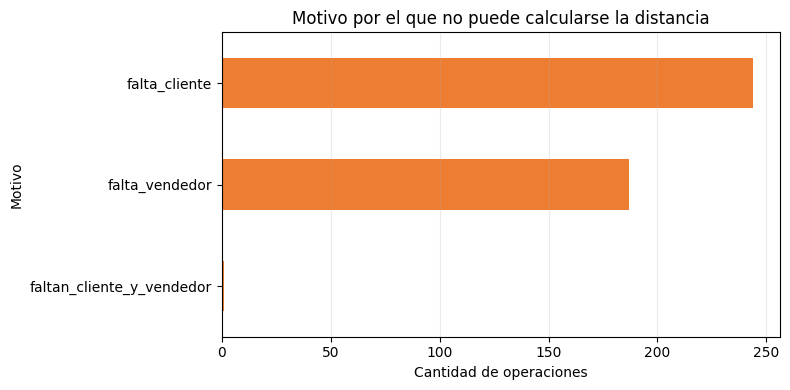

Estados de clientes sin geolocalización dentro de la muestra:


,operaciones
estado,
DF,149
RJ,13
SP,13
PR,11
GO,9
MG,9
BA,7
ES,6
PE,4


In [9]:
motivos_faltantes = (
    base.loc[~base["distancia_disponible"], "motivo_sin_distancia"]
    .value_counts()
    .sort_values(ascending=True)
)

fig, ax = plt.subplots(figsize=(8, 4))
motivos_faltantes.plot(kind="barh", ax=ax, color="#ED7D31")
ax.set_title("Motivo por el que no puede calcularse la distancia")
ax.set_xlabel("Cantidad de operaciones")
ax.set_ylabel("Motivo")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

print("Estados de clientes sin geolocalización dentro de la muestra:")
display(
    base.loc[~base["cliente_geo_disponible"], "customer_state"]
    .value_counts()
    .rename_axis("estado")
    .to_frame("operaciones")
)

In [10]:
sin_distancia = base.loc[
    ~base["distancia_disponible"],
    [
        "order_id",
        "customer_unique_id",
        "customer_zip_code_prefix",
        "customer_city",
        "customer_state",
        "seller_id",
        "seller_zip_code_prefix",
        "seller_city",
        "seller_state",
        "motivo_sin_distancia",
    ],
].copy()

print("Ejemplo de operaciones que requieren tratamiento metodológico:")
display(sin_distancia.head(10))

Ejemplo de operaciones que requieren tratamiento metodológico:


,order_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,seller_id,seller_zip_code_prefix,seller_city,seller_state,motivo_sin_distancia
386,690199d6a2c51ff57c6b392d7680cbfd,c5f01991eadc43c924dfd891e9026217,87323,alto sao joao,PR,cc419e0650a3c5ba77189a1882b7556a,9015,santo andre,SP,falta_cliente
531,9f2da077d2d1eb6e8abcacef8776e941,ab7bed4092cc3dadbaefba86cb45f37f,73081,brasilia,DF,bbad7e518d7af88a0897397ffdca1979,1512,sao paulo,SP,falta_cliente
593,1b00c4d80c81cdbc36487c96c6e92f07,5399c9213ca365a480537a1b21423d2c,28160,santo eduardo,RJ,2f09f7d37a97956d11cc1a7cadd5262b,14090,ribeirao preto,SP,falta_cliente
671,d445a6e277eaa62900bc18d453d96d76,e808aa0ce98f33e671bf3e5b47756564,69918,rio branco,AC,42bde9fef835393bb8a8849cb6b7f245,71551,brasilia,DF,falta_vendedor
952,d0bec96aad189992b278688279ba1511,67b05b597a66b5c449025000b9430abb,64605,picos,PI,7d13fca15225358621be4086e1eb0964,14050,ribeirao preto,SP,falta_cliente
1015,c774090f7e672d0718f1ea7e9a3a8590,07a421ede5046fc7bf8af5609afaa05c,13561,sao carlos,SP,42bde9fef835393bb8a8849cb6b7f245,71551,brasilia,DF,falta_vendedor
1052,695e141b92a0f2bc8a7bff7d621692ed,1c39144d899f035157a7761e319bc3ea,71676,brasilia,DF,9f505651f4a6abe901a56cdc21508025,4102,sao paulo,SP,falta_cliente
1079,9a65fd6f0966e358fbae4d1b54f73ccd,17607d71527c1aeba58519710396a4bc,77001,palmas,TO,2e90cb1677d35cfe24eef47d441b7c87,2285,sao paulo,SP,falta_vendedor
1185,4519d054994236d26b04aba27498afb9,60b1b4c715a06c7120279bc8da388fd2,37250,nepomuceno,MG,2e90cb1677d35cfe24eef47d441b7c87,2285,sao paulo,SP,falta_vendedor
1198,bf7dc4793cf928d5303528934bd9647c,be570271e817b7a8791c477152830384,28470,santo antonio de padua,RJ,870d0118f7a9d85960f29ad89d5d989a,37708,pocos de caldas,MG,falta_vendedor


## 6. Criterio metodológico para el tratamiento de la cobertura geográfica

El análisis muestra que la ausencia de coordenadas no se origina en valores nulos de las tablas de clientes o vendedores, sino en prefijos postales que no encuentran correspondencia en la tabla de geolocalización. Para la muestra de pedidos entregados con un único ítem, esta situación impide calcular la distancia en 432 de 86.843 operaciones, equivalentes al 0,497 % de la muestra.

En el análisis principal se trabajará con las operaciones que dispongan de coordenadas tanto para el cliente como para el vendedor. No se imputarán coordenadas en esta instancia, dado que reemplazar un prefijo postal faltante por un centroide de ciudad o estado introduciría una escala geográfica diferente de la utilizada en el resto de las observaciones. Esa aproximación podría alterar de manera artificial la distancia y dificultar la interpretación del aporte incremental de la variable geográfica.

Los modelos M0, M1, M2 y M3 deberán estimarse y evaluarse sobre el mismo conjunto de observaciones completas. Mantener una muestra común permite que las diferencias de MAE y RMSE se atribuyan a los bloques de variables incorporados en cada modelo y no a cambios en la composición de los datos. Las operaciones excluidas se conservarán en una tabla de diagnóstico junto con indicadores que identifiquen si falta la geolocalización del cliente, del vendedor o de ambos.

Aunque la proporción de casos sin distancia es reducida, su distribución no es territorialmente homogénea y presenta una concentración relevante en Distrito Federal. Por lo tanto, la exclusión no debe interpretarse automáticamente como completamente aleatoria. Se documentará la distribución de los casos excluidos y, como análisis de sensibilidad, se podrá comparar el resultado principal con una variante que utilice centroides de ciudad y estado. Esta comparación permitirá evaluar si el tratamiento de la cobertura geográfica modifica las conclusiones del estudio.

In [11]:
total = len(base)
utilizables = int(base["distancia_disponible"].sum())
no_utilizables = total - utilizables
porcentaje_utilizable = 100 * utilizables / total

print("Conclusión del EDA")
print("-" * 60)
print("Los clientes y vendedores tienen su prefijo postal informado.")
print("El faltante aparece cuando algunos prefijos no existen en geolocalización.")
print(f"Muestra principal: {total:,} operaciones.")
print(f"Distancia calculable: {utilizables:,} operaciones ({porcentaje_utilizable:.3f}%).")
print(f"Sin distancia calculable: {no_utilizables:,} operaciones.")

Conclusión del EDA
------------------------------------------------------------
Los clientes y vendedores tienen su prefijo postal informado.
El faltante aparece cuando algunos prefijos no existen en geolocalización.
Muestra principal: 86,843 operaciones.
Distancia calculable: 86,411 operaciones (99.503%).
Sin distancia calculable: 432 operaciones.
